<a href="https://colab.research.google.com/github/20deepak28/Customer-Lifetime-Value-Churn-Intelligence/blob/main/02_Exploratory_data_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Mounting Drive

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


### LOAD THE PROCESSED DATASET

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

sns.set_theme(style="whitegrid")

project_path = '/content/drive/MyDrive/Customer-Lifetime-Value-Churn-Intelligence'

data_path = os.path.join(project_path, 'data')

df = pd.read_csv(
    os.path.join(data_path, 'telco_churn_processed.csv')
)

print("Dataset loaded:", df.shape)

Dataset loaded: (7043, 21)


### Customer Overview

In [4]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692,2279.734304
std,0.368612,24.559481,30.090047,2266.794470
min,0.000000,0.000000,18.250000,0.000000
25%,0.000000,9.000000,35.500000,398.550000
50%,0.000000,29.000000,70.350000,1394.550000
75%,0.000000,55.000000,89.850000,3786.600000
max,1.000000,72.000000,118.750000,8684.800000


In [5]:
categorical_cols = df.select_dtypes(include='object').columns

for col in categorical_cols:
    print(f"\n{col}")
    print(df[col].value_counts())


customerID
customerID
7590-VHVEG    1
5575-GNVDE    1
3668-QPYBK    1
7795-CFOCW    1
9237-HQITU    1
             ..
6840-RESVB    1
2234-XADUH    1
4801-JZAZL    1
8361-LTMKD    1
3186-AJIEK    1
Name: count, Length: 7043, dtype: int64

gender
gender
Male      3555
Female    3488
Name: count, dtype: int64

Partner
Partner
No     3641
Yes    3402
Name: count, dtype: int64

Dependents
Dependents
No     4933
Yes    2110
Name: count, dtype: int64

PhoneService
PhoneService
Yes    6361
No      682
Name: count, dtype: int64

MultipleLines
MultipleLines
No                  3390
Yes                 2971
No phone service     682
Name: count, dtype: int64

InternetService
InternetService
Fiber optic    3096
DSL            2421
No             1526
Name: count, dtype: int64

OnlineSecurity
OnlineSecurity
No                     3498
Yes                    2019
No internet service    1526
Name: count, dtype: int64

OnlineBackup
OnlineBackup
No                     3088
Yes                    2429


### Visualize customer demographics

* Is our customer base balanced by gender?
* How many customers are senior citizens?
* How many customers have partners?

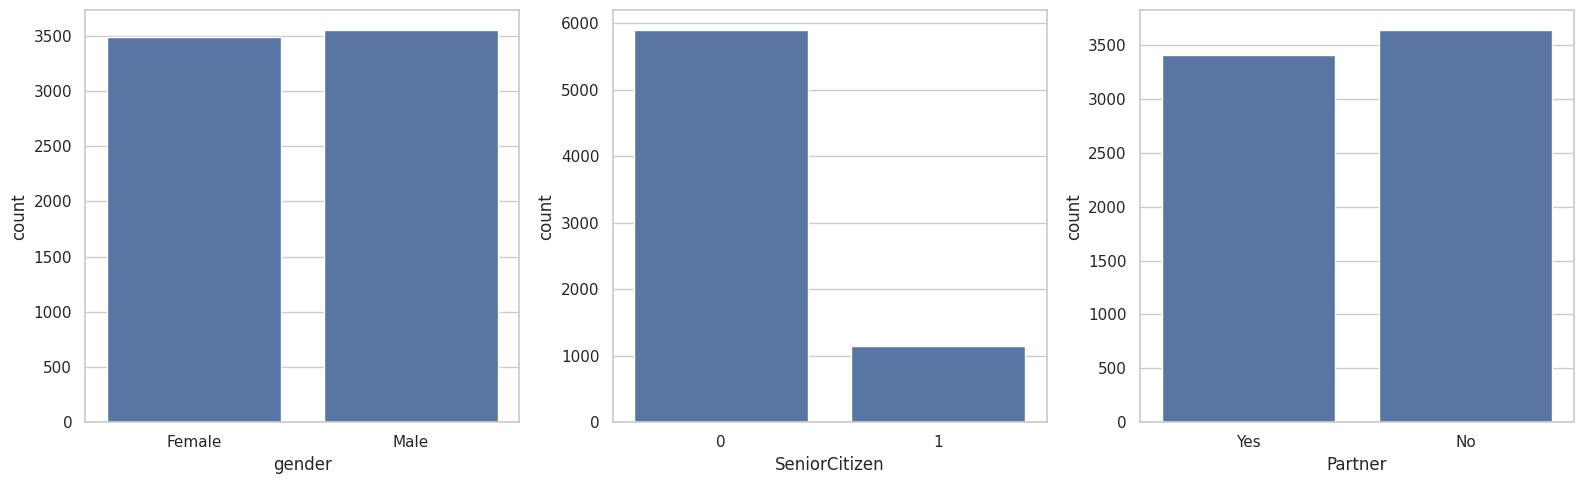

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

sns.countplot(data=df, x='gender', ax=axes[0])
sns.countplot(data=df, x='SeniorCitizen', ax=axes[1])
sns.countplot(data=df, x='Partner', ax=axes[2])

plt.tight_layout()
plt.show()

### Churn Distributions

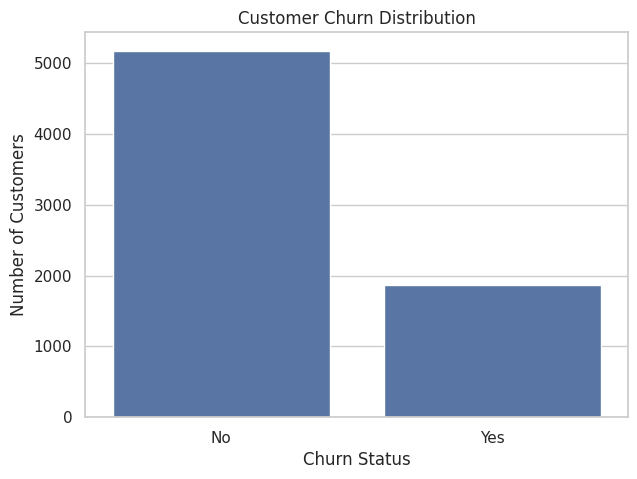

In [7]:
churn_counts = df['Churn'].value_counts()

plt.figure(figsize=(7, 5))

sns.countplot(data=df, x='Churn')

plt.title('Customer Churn Distribution')
plt.xlabel('Churn Status')
plt.ylabel('Number of Customers')

plt.show()

### Calculate percentages

In [8]:
churn_percentage = df['Churn'].value_counts(normalize=True) * 100

print(churn_percentage.round(2))

Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64


### Tenure Analysis

 * Do customers who leave generally have shorter tenure?

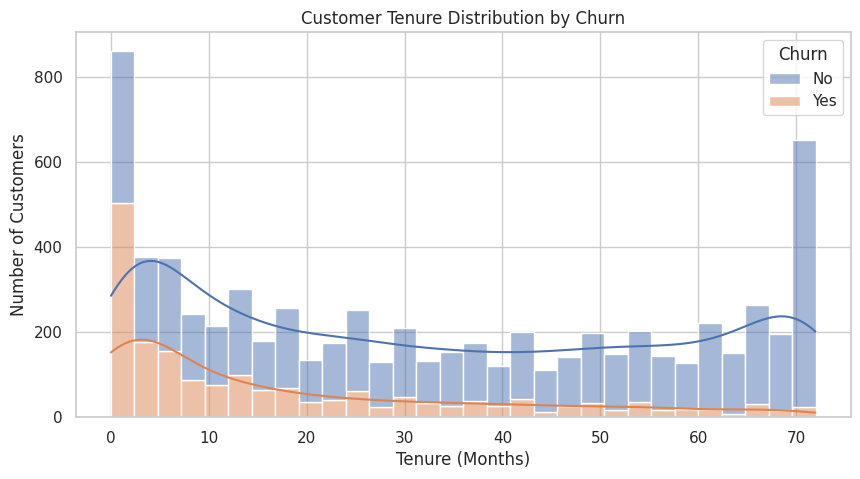

In [9]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x='tenure',
    hue='Churn',
    bins=30,
    kde=True,
    multiple='stack'
)

plt.title('Customer Tenure Distribution by Churn')
plt.xlabel('Tenure (Months)')
plt.ylabel('Number of Customers')

plt.show()

In [10]:
df.groupby('Churn')['tenure'].mean()

,tenure
Churn,
No,37.569965
Yes,17.979133


### Contract Analysis

In [11]:
contract_churn = pd.crosstab(
    df['Contract'],
    df['Churn'],
    normalize='index'
) * 100

display(contract_churn.round(2))

Churn,No,Yes
Contract,,
Month-to-month,57.29,42.71
One year,88.73,11.27
Two year,97.17,2.83


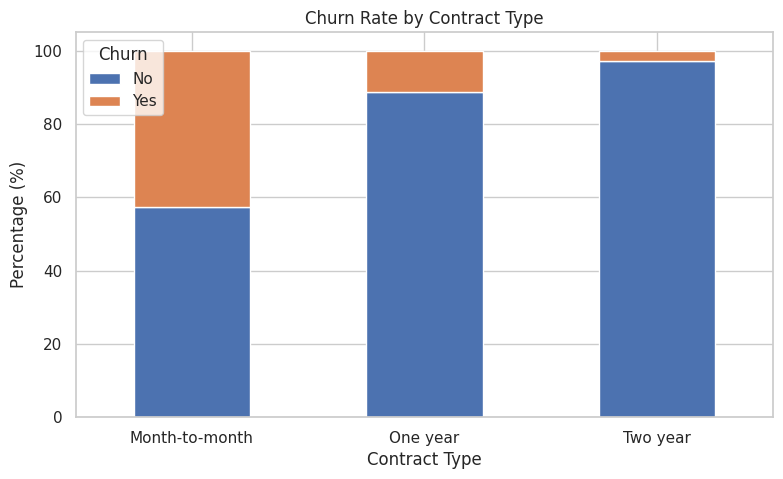

In [12]:
contract_churn.plot(
    kind='bar',
    stacked=True,
    figsize=(9, 5)
)

plt.title('Churn Rate by Contract Type')
plt.xlabel('Contract Type')
plt.ylabel('Percentage (%)')
plt.xticks(rotation=0)
plt.legend(title='Churn')

plt.show()

### Contract Analysis — Key Findings

- Month-to-month customers have the highest churn rate (~43%).
- One-year contract customers show considerably lower churn (~11%).
- Two-year contract customers have the lowest churn (~3%).

**Business Insight:** Longer-term contracts are strongly associated with better customer retention. The company could introduce incentives to encourage customers to adopt longer-term contracts.

### Monthly Charges Analysis

#### Visualize

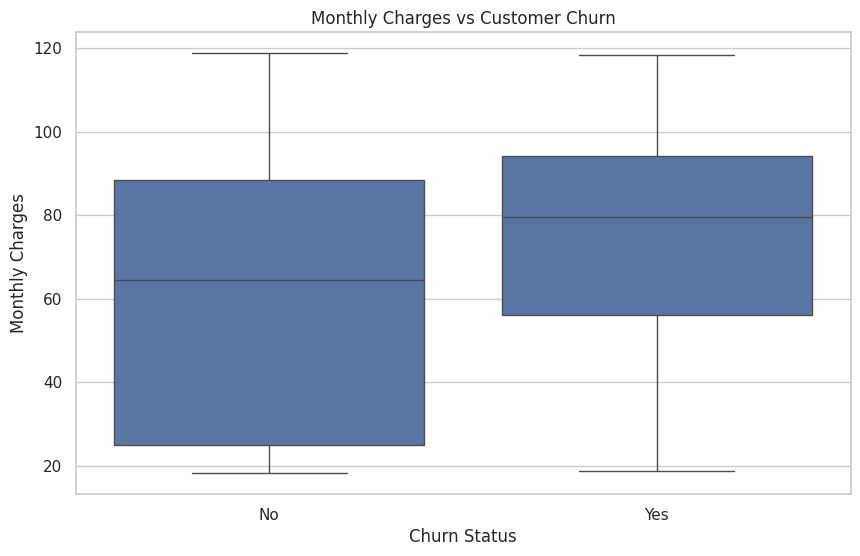

In [13]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x='Churn',
    y='MonthlyCharges'
)

plt.title('Monthly Charges vs Customer Churn')
plt.xlabel('Churn Status')
plt.ylabel('Monthly Charges')

plt.show()

#### Compare average monthly charges

In [14]:
df.groupby('Churn')['MonthlyCharges'].agg(
    ['mean', 'median', 'min', 'max']
).round(2)

,mean,median,min,max
Churn,,,,
No,61.27,64.43,18.25,118.75
Yes,74.44,79.65,18.85,118.35


#### Analyze monthly charges by contract and churn

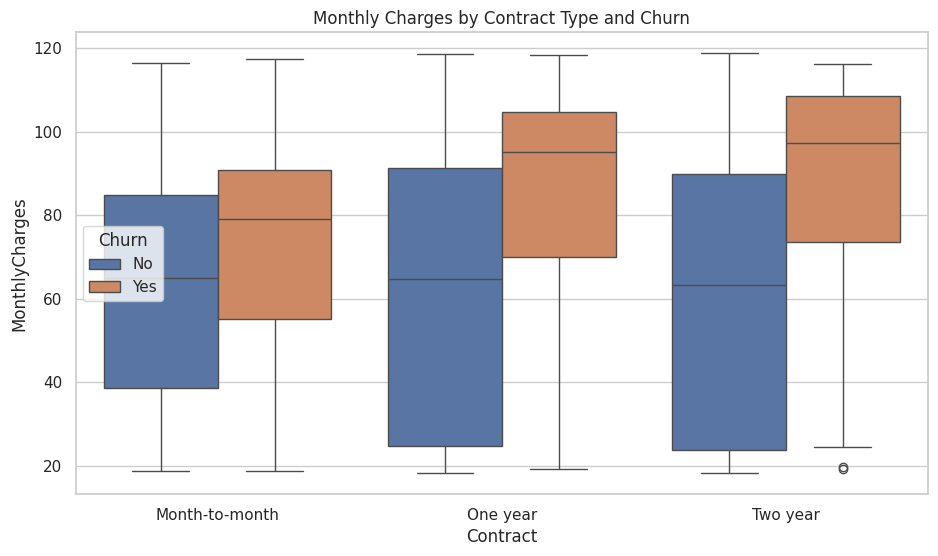

In [15]:
plt.figure(figsize=(11, 6))

sns.boxplot(
    data=df,
    x='Contract',
    y='MonthlyCharges',
    hue='Churn'
)

plt.title('Monthly Charges by Contract Type and Churn')
plt.show()

### Monthly Charges Analysis — Key Findings

- Churned customers have a higher average monthly charge ($74.44) than retained customers ($61.27).
- The median monthly charge is also higher among churned customers ($79.65 vs $64.43).
- Higher monthly charges are associated with increased churn across contract categories.

**Business Insight:** The company should investigate pricing strategies, perceived service value and customer affordability to improve retention.

## Payment Method Analysis

### Calculate churn % by payment method

In [16]:
payment_churn = pd.crosstab(
    df['PaymentMethod'],
    df['Churn'],
    normalize='index'
) * 100

display(payment_churn.round(2))

Churn,No,Yes
PaymentMethod,,
Bank transfer (automatic),83.29,16.71
Credit card (automatic),84.76,15.24
Electronic check,54.71,45.29
Mailed check,80.89,19.11


### Visualize payment method distribution

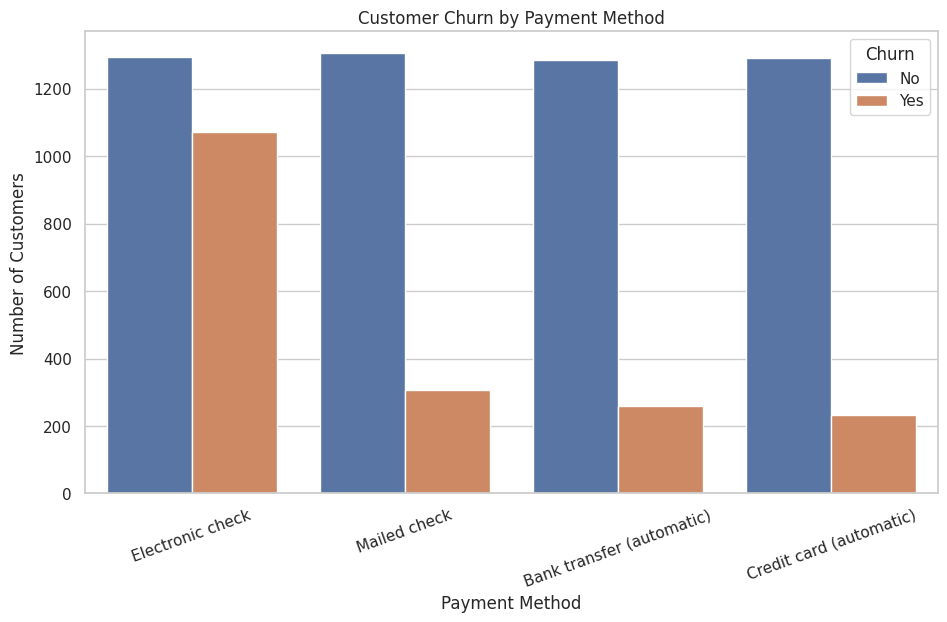

In [17]:
plt.figure(figsize=(11, 6))

sns.countplot(
    data=df,
    x='PaymentMethod',
    hue='Churn'
)

plt.title('Customer Churn by Payment Method')
plt.xlabel('Payment Method')
plt.ylabel('Number of Customers')
plt.xticks(rotation=20)

plt.show()

### Visualize churn percentage

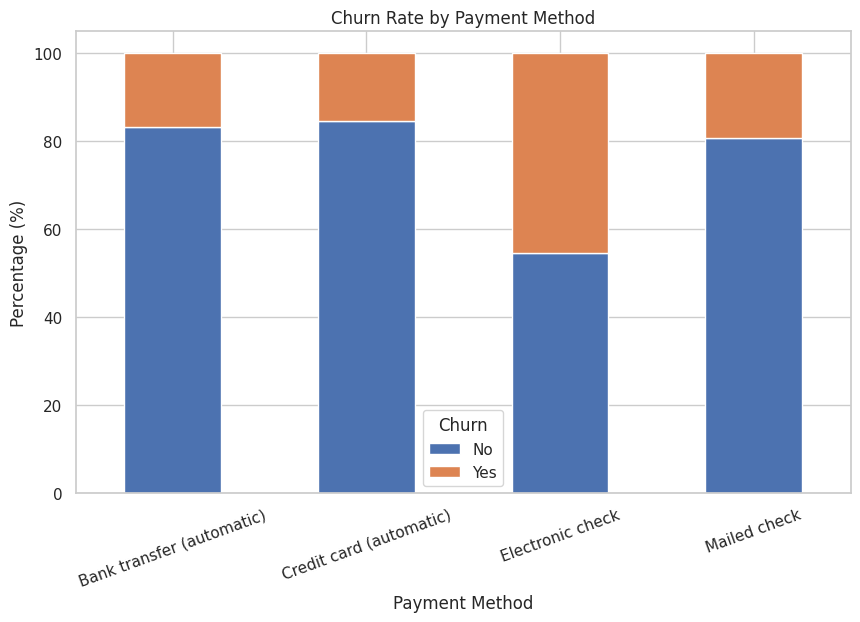

In [18]:
payment_churn.plot(
    kind='bar',
    stacked=True,
    figsize=(10, 6)
)

plt.title('Churn Rate by Payment Method')
plt.xlabel('Payment Method')
plt.ylabel('Percentage (%)')
plt.xticks(rotation=20)
plt.legend(title='Churn')

plt.show()

### Payment Method Analysis — Key Findings

- Electronic Check users have the highest churn rate (~45%).
- Mailed Check users have a churn rate of approximately 19%.
- Automatic Bank Transfer and Credit Card users show lower churn rates (~17% and ~15%).

**Business Insight:** The company could encourage automatic payment adoption through convenient payment options and incentives. Electronic Check users should be investigated as a high-priority retention segment.

## Internet Service Analysis

### Calculate churn Percentage

In [19]:
internet_churn = pd.crosstab(
    df['InternetService'],
    df['Churn'],
    normalize='index'
) * 100

display(internet_churn.round(2))

Churn,No,Yes
InternetService,,
DSL,81.04,18.96
Fiber optic,58.11,41.89
No,92.60,7.40


### Visualize churn distribution

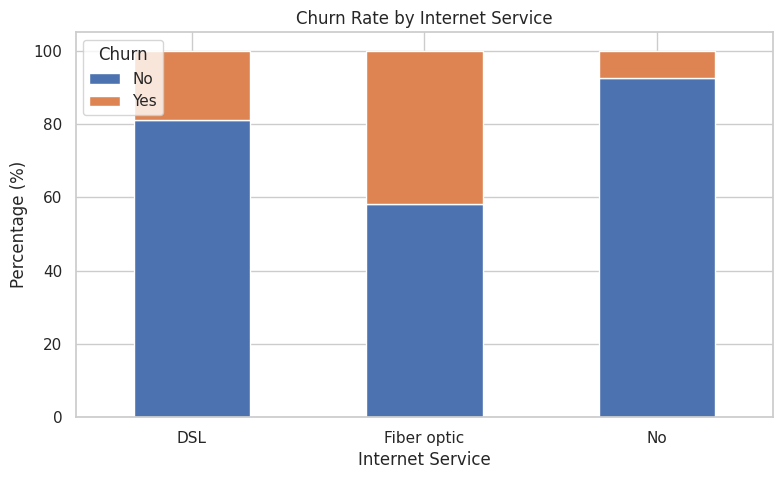

In [20]:
internet_churn.plot(
    kind='bar',
    stacked=True,
    figsize=(9, 5)
)

plt.title('Churn Rate by Internet Service')
plt.xlabel('Internet Service')
plt.ylabel('Percentage (%)')
plt.xticks(rotation=0)
plt.legend(title='Churn')

plt.show()

### Compare monthly charges

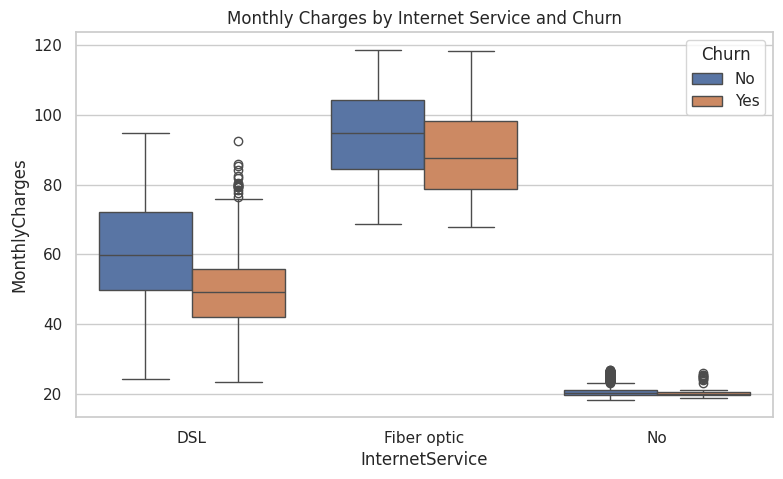

In [21]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x='InternetService',
    y='MonthlyCharges',
    hue='Churn'
)

plt.title('Monthly Charges by Internet Service and Churn')
plt.show()

### Internet Service Analysis — Key Findings

- Fiber Optic customers have the highest churn rate (41.89%).
- DSL customers have a considerably lower churn rate (18.96%).
- Customers without internet service have the lowest churn rate (7.40%).
- Fiber Optic customers generally have higher monthly charges.

**Business Insight:** Fiber Optic customers represent an important retention segment. The company should investigate service quality, pricing and customer satisfaction to understand their higher churn rate.

## Additional Services Analysis

#### Calculate churn rates for all services

In [22]:
service_columns = [
    'OnlineSecurity',
    'OnlineBackup',
    'DeviceProtection',
    'TechSupport',
    'StreamingTV',
    'StreamingMovies'
]

for col in service_columns:

    print(f"\n{col}")

    result = pd.crosstab(
        df[col],
        df['Churn'],
        normalize='index'
    ) * 100

    display(result.round(2))


OnlineSecurity


Churn,No,Yes
OnlineSecurity,,
No,58.23,41.77
No internet service,92.60,7.40
Yes,85.39,14.61



OnlineBackup


Churn,No,Yes
OnlineBackup,,
No,60.07,39.93
No internet service,92.60,7.40
Yes,78.47,21.53



DeviceProtection


Churn,No,Yes
DeviceProtection,,
No,60.87,39.13
No internet service,92.60,7.40
Yes,77.50,22.50


... (2 outputs left out)


StreamingTV


Churn,No,Yes
StreamingTV,,
No,66.48,33.52
No internet service,92.60,7.40
Yes,69.93,30.07



StreamingMovies


Churn,No,Yes
StreamingMovies,,
No,66.32,33.68
No internet service,92.60,7.40
Yes,70.06,29.94


### Visualize churn rates

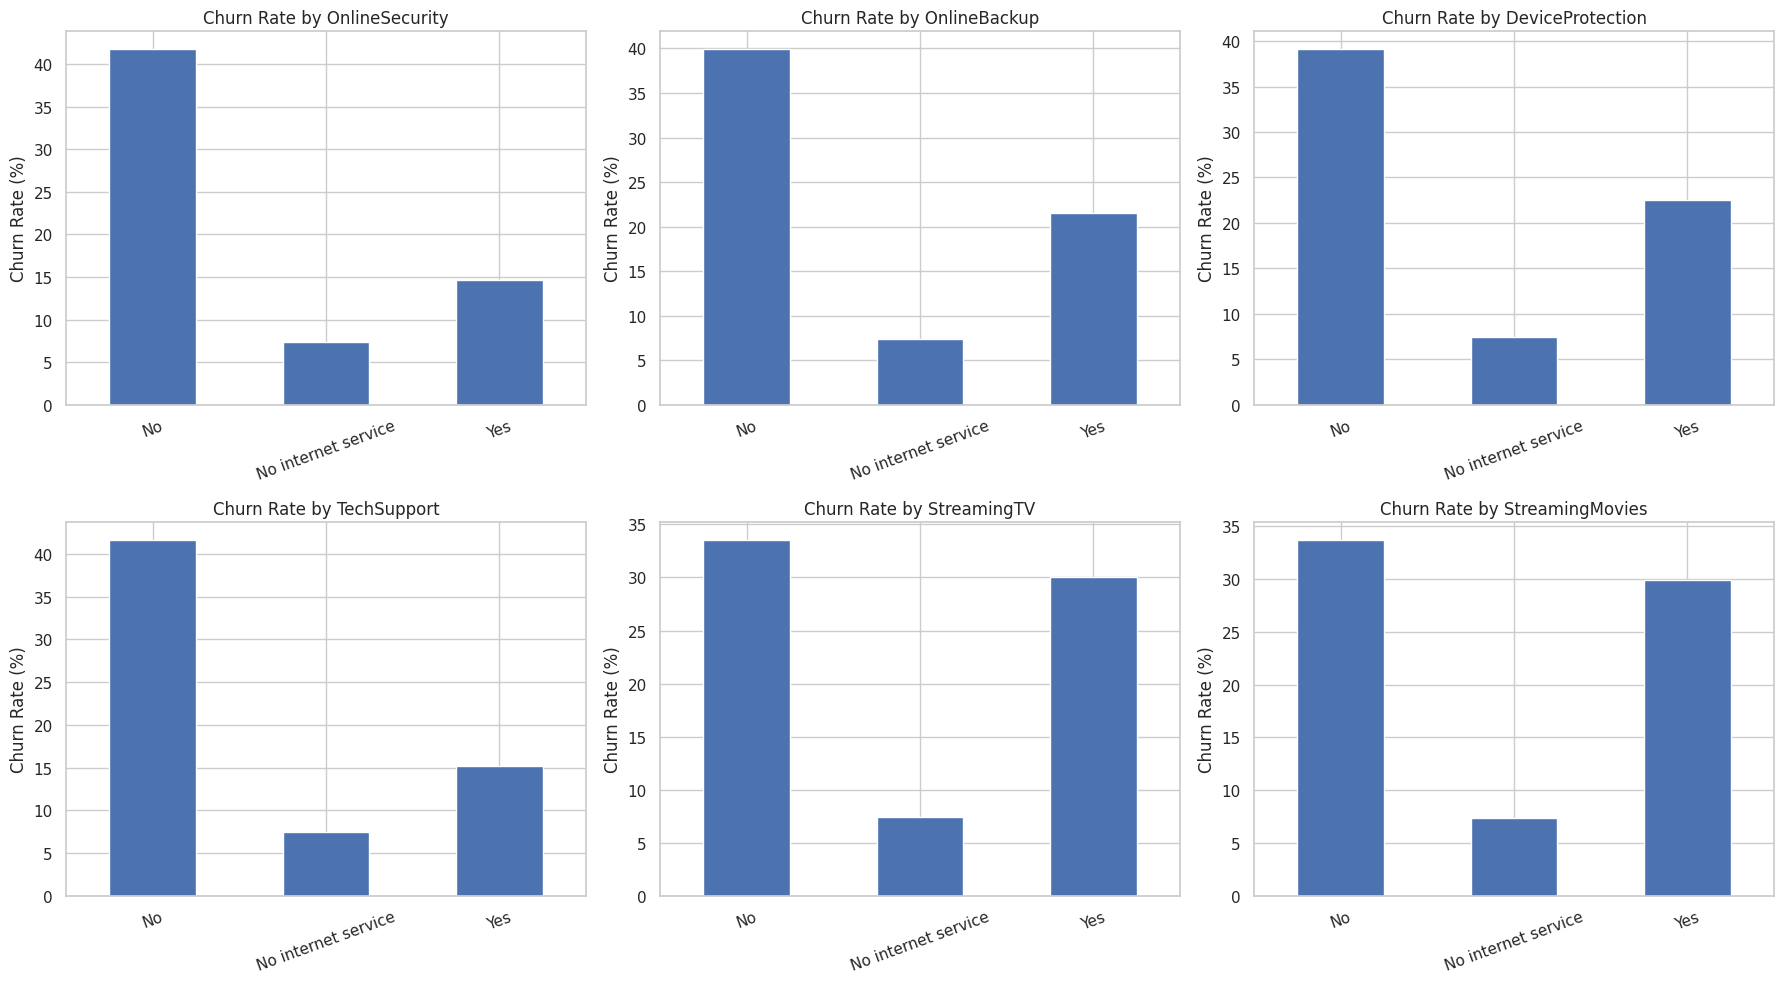

In [23]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

for col, ax in zip(service_columns, axes.flatten()):

    churn_rate = pd.crosstab(
        df[col],
        df['Churn'],
        normalize='index'
    ) * 100

    churn_rate['Yes'].plot(
        kind='bar',
        ax=ax
    )

    ax.set_title(f'Churn Rate by {col}')
    ax.set_ylabel('Churn Rate (%)')
    ax.set_xlabel('')
    ax.tick_params(axis='x', rotation=20)

plt.tight_layout()
plt.show()

### Additional Services Analysis — Key Findings

- Customers without Online Security have higher churn (41.77%) compared to subscribers (14.61%).
- Customers without Tech Support show 41.64% churn, compared to 15.17% among subscribers.
- Online Backup and Device Protection are also associated with lower churn.
- Streaming TV and Movies show relatively weaker relationships with churn.

**Business Insight:** Online Security and Tech Support are promising factors for customer retention analysis. The company should investigate whether these services contribute to improved customer loyalty.

## Correlation Analysis

### Create a numerical target variable

In [24]:
df['Churn_Binary'] = df['Churn'].map({
    'No': 0,
    'Yes': 1
})

### Calculate Correlation

In [25]:
numerical_cols = [
    'tenure',
    'MonthlyCharges',
    'TotalCharges',
    'SeniorCitizen',
    'Churn_Binary'
]

correlation_matrix = df[numerical_cols].corr()

display(correlation_matrix.round(3))

,tenure,MonthlyCharges,TotalCharges,SeniorCitizen,Churn_Binary
tenure,1.000,0.248,0.826,0.017,-0.352
MonthlyCharges,0.248,1.000,0.651,0.220,0.193
TotalCharges,0.826,0.651,1.000,0.103,-0.198
SeniorCitizen,0.017,0.220,0.103,1.000,0.151
Churn_Binary,-0.352,0.193,-0.198,0.151,1.000


### Visualize the correlation matrix

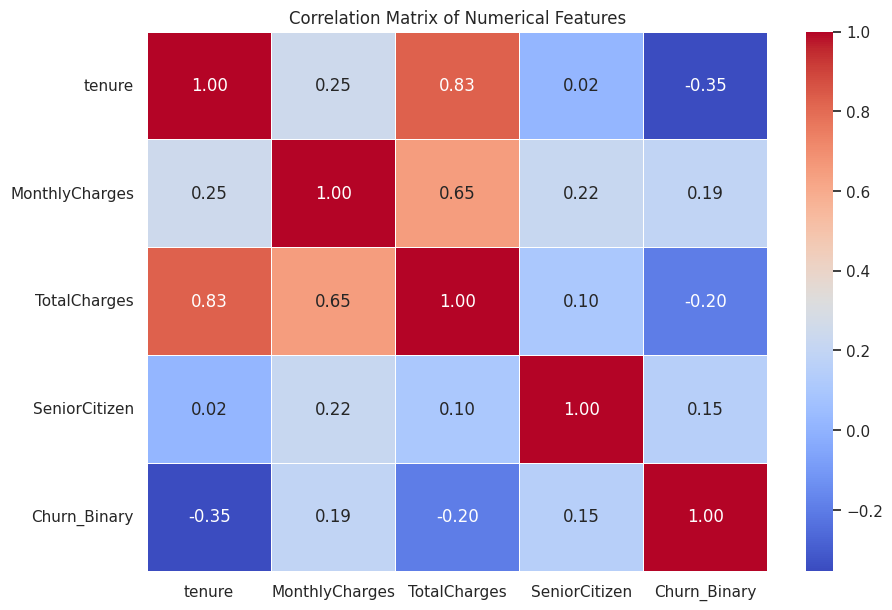

In [26]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Matrix of Numerical Features')

plt.show()

### Identify features corelatedd with churn

In [27]:
churn_correlation = (
    correlation_matrix['Churn_Binary']
    .drop('Churn_Binary')
    .sort_values(ascending=False)
)

print(churn_correlation)

MonthlyCharges    0.193356
SeniorCitizen     0.150889
TotalCharges     -0.198324
tenure           -0.352229
Name: Churn_Binary, dtype: float64


### Correlation Analysis — Key Findings

- Tenure has the strongest negative correlation with churn (-0.352).
- MonthlyCharges has a weak positive correlation with churn (+0.193).
- TotalCharges has a negative correlation with churn (-0.198).
- SeniorCitizen has a weak positive correlation with churn (+0.151).
- Tenure and TotalCharges are strongly correlated (+0.826).

**Conclusion:** Tenure appears to be an important numerical indicator of customer churn. Correlation does not imply causation, and further evaluation through machine learning is required.